In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
import re 
from sklearn.preprocessing import OneHotEncoder,LabelEncoder
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report,r2_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer 
import joblib 

In [2]:
df= pd.read_csv('india_scam_sms_50k.csv')

In [3]:
df.head()

,text,label,binary_label,language,source
0,Your power connection will be disconnected at ...,scam_electricity,scam,english,synthetic
1,"Free iPhone jeetne ka mauka, abhi click karein...",spam_promo,spam,hinglish,synthetic
2,"Aapka courier deliver nahi ho paya, 2 ghante m...",scam_courier,scam,hinglish,synthetic
3,"Dear Customer, Your loan EMI is overdue. Legal...",scam_loan,scam,english,synthetic
4,"hello customer, loan app alert: repay rs 1,99...",scam_loan,scam,english,synthetic


In [4]:
df.isnull().sum()

text            0
label           0
binary_label    0
language        0
source          0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
df.drop_duplicates()

,text,label,binary_label,language,source
0,Your power connection will be disconnected at ...,scam_electricity,scam,english,synthetic
1,"Free iPhone jeetne ka mauka, abhi click karein...",spam_promo,spam,hinglish,synthetic
2,"Aapka courier deliver nahi ho paya, 2 ghante m...",scam_courier,scam,hinglish,synthetic
3,"Dear Customer, Your loan EMI is overdue. Legal...",scam_loan,scam,english,synthetic
4,"hello customer, loan app alert: repay rs 1,99...",scam_loan,scam,english,synthetic
...,...,...,...,...,...
49995,"Notice: Rs 4,500 credited to your A/c XX7460. ...",legit,legit,english,synthetic
49996,FLIPKART: PINCODE GALAT HONE SE PARCEL DELIVER...,scam_courier,scam,hinglish,synthetic
49997,dtdc delivery failed. reschedule within 2 hrs ...,scam_courier,scam,english,synthetic
49998,"get rs 8,750 personal loan in 2 minutes with o...",scam_loan,scam,english,synthetic


In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
# def clean_text(text):
#     text=str(text)

#     text=text.lower()

#     text=re.sub(r'[^a-zA-Z0-9\s]','',text)

#     text=re.sub(r'\s+',' ',text).strip()
#     return text 


In [9]:
# df['text']=df['text'].apply(clean_text)

In [10]:
df

,text,label,binary_label,language,source
0,Your power connection will be disconnected at ...,scam_electricity,scam,english,synthetic
1,"Free iPhone jeetne ka mauka, abhi click karein...",spam_promo,spam,hinglish,synthetic
2,"Aapka courier deliver nahi ho paya, 2 ghante m...",scam_courier,scam,hinglish,synthetic
3,"Dear Customer, Your loan EMI is overdue. Legal...",scam_loan,scam,english,synthetic
4,"hello customer, loan app alert: repay rs 1,99...",scam_loan,scam,english,synthetic
...,...,...,...,...,...
49995,"Notice: Rs 4,500 credited to your A/c XX7460. ...",legit,legit,english,synthetic
49996,FLIPKART: PINCODE GALAT HONE SE PARCEL DELIVER...,scam_courier,scam,hinglish,synthetic
49997,dtdc delivery failed. reschedule within 2 hrs ...,scam_courier,scam,english,synthetic
49998,"get rs 8,750 personal loan in 2 minutes with o...",scam_loan,scam,english,synthetic


In [11]:
import re
import pandas as pd

def clean_text(text):

    # Handle missing values
    if pd.isna(text):
        return ""

    text = str(text).lower()

    # 1. Replace URLs
    text = re.sub(
        r'(https?://\S+|www\.\S+)',
        ' URL ',
        text
    )

    # 2. Replace email addresses
    text = re.sub(
        r'\b[a-z0-9._%+-]+@[a-z0-9.-]+\.[a-z]{2,}\b',
        ' EMAIL ',
        text
    )

    # 3. Replace phone numbers
    text = re.sub(
        r'(?<!\w)(?:\+?\d{1,3}[-.\s]?)?(?:\d[-.\s]?){9,12}(?!\w)',
        ' PHONE ',
        text
    )

    # 4. Preserve currency information
    text = re.sub(
        r'₹|rs\.?|inr|usd|\$|€|£',
        ' CURRENCY ',
        text
    )

    # 5. Normalize common obfuscated characters
    char_map = str.maketrans({
        '@': 'a',
        '€': 'e',
        '£': 'e',
        '!': 'i'
    })

    text = text.translate(char_map)

    # 6. Preserve numerical amounts and quantities
    # (Numbers are retained for classification)

    # 7. Remove remaining special characters
    text = re.sub(r'[^a-z0-9\s]', ' ', text)

    # 8. Remove extra whitespace
    text = re.sub(r'\s+', ' ', text).strip()

    return text


df['clean_message'] = df['text'].apply(clean_text)

In [12]:
df['clean_message']

0        your power connection will be disconnected at ...
1        free iphone jeetne ka mauka abhi click karein ...
2        aapka courier deliver nahi ho paya 2 ghante me...
3        dear customer your loan emi is overdue legal n...
4        hello customer loan app alert repay 1 999 toda...
                               ...                        
49995    notice 4 500 credited to your a c xx7460 avail...
49996    flipkart pincode galat hone se parcel deliver ...
49997    dtdc delivery failed reschedule within 2 h or ...
49998    get 8 750 pe onal loan in 2 minutes with only ...
49999    aapka aadhaar axis a c se link nahi hai aaj hi...
Name: clean_message, Length: 50000, dtype: str

In [13]:
df.drop(columns={'text','label'},inplace=True)

C:\Users\Riju\AppData\Local\Temp\ipykernel_28320\3747222997.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns={'text','label'},inplace=True)


In [14]:
df

,binary_label,language,source,clean_message
0,scam,english,synthetic,your power connection will be disconnected at ...
1,spam,hinglish,synthetic,free iphone jeetne ka mauka abhi click karein ...
2,scam,hinglish,synthetic,aapka courier deliver nahi ho paya 2 ghante me...
3,scam,english,synthetic,dear customer your loan emi is overdue legal n...
4,scam,english,synthetic,hello customer loan app alert repay 1 999 toda...
...,...,...,...,...
49995,legit,english,synthetic,notice 4 500 credited to your a c xx7460 avail...
49996,scam,hinglish,synthetic,flipkart pincode galat hone se parcel deliver ...
49997,scam,english,synthetic,dtdc delivery failed reschedule within 2 h or ...
49998,scam,english,synthetic,get 8 750 pe onal loan in 2 minutes with only ...


In [15]:
df_cleaned_1=df

In [16]:
df_cleaned_1['source'].value_counts()

source
synthetic    47959
real          2041
Name: count, dtype: int64

In [17]:
df_cleaned_1['binary_label'].value_counts()

binary_label
scam     29882
legit    13960
spam      6158
Name: count, dtype: int64

In [18]:
df_cleaned_1.head()

,binary_label,language,source,clean_message
0,scam,english,synthetic,your power connection will be disconnected at ...
1,spam,hinglish,synthetic,free iphone jeetne ka mauka abhi click karein ...
2,scam,hinglish,synthetic,aapka courier deliver nahi ho paya 2 ghante me...
3,scam,english,synthetic,dear customer your loan emi is overdue legal n...
4,scam,english,synthetic,hello customer loan app alert repay 1 999 toda...


In [19]:
cat_col=['language','source']
text_col=['clean_message']

In [20]:
df_cleaned_1.shape

(50000, 4)

In [21]:
df_cleaned_1.columns

Index(['binary_label', 'language', 'source', 'clean_message'], dtype='str')

In [22]:
df_cleaned_1.head()

,binary_label,language,source,clean_message
0,scam,english,synthetic,your power connection will be disconnected at ...
1,spam,hinglish,synthetic,free iphone jeetne ka mauka abhi click karein ...
2,scam,hinglish,synthetic,aapka courier deliver nahi ho paya 2 ghante me...
3,scam,english,synthetic,dear customer your loan emi is overdue legal n...
4,scam,english,synthetic,hello customer loan app alert repay 1 999 toda...


In [23]:
# x=df_cleaned_1[['clean_message']+cat_col]
# y=df_cleaned_1['binary_label']

# x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [24]:
preprocessor=ColumnTransformer(transformers=[
    ('txt',CountVectorizer(),'clean_message'),
    ('cat',OneHotEncoder(handle_unknown='ignore'),cat_col)
])

In [25]:
model = Pipeline(steps = [
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter = 1000, class_weight = 'balanced'))
])
# model.fit(x_train, y_train)

In [26]:
# y_pred = model.predict(x_test)

# print("Accuracy:", accuracy_score(y_test, y_pred))
# print(classification_report(y_test, y_pred))


In [27]:
# y_train_pred = model.predict(x_train)
# y_test_pred = model.predict(x_test)

# print("Training Accuracy:",
#       accuracy_score(y_train, y_train_pred))

# print("Testing Accuracy:",
#       accuracy_score(y_test, y_test_pred))

In [28]:
# print(df_cleaned_1['clean_message'].duplicated().sum())

In [29]:
# train_messages = set(x_train['clean_message'])
# test_messages = set(x_test['clean_message'])

# common_messages = train_messages.intersection(test_messages)

# print("Messages appearing in both datasets:",
#       len(common_messages))

In [30]:
# from sklearn.metrics import ConfusionMatrixDisplay
# import matplotlib.pyplot as plt

# ConfusionMatrixDisplay.from_predictions(
#     y_test, y_pred
# )

# plt.show()

In [32]:
df_clean = df_cleaned_1.drop_duplicates(
    subset=['clean_message'],
    keep='first'
).reset_index(drop=True)

print("Original rows:", len(df_cleaned_1))
print("After removing duplicates:", len(df_clean))
print("Removed rows:", len(df_cleaned_1) - len(df_clean))

Original rows: 50000
After removing duplicates: 45195
Removed rows: 4805


In [33]:
X = df_clean[['clean_message']+cat_col]
y = df_clean['binary_label']

x_train, x_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [34]:
model.fit(x_train, y_train)

print("Training Accuracy:",
      model.score(x_train, y_train))

print("Testing Accuracy:",
      model.score(x_test, y_test))

Training Accuracy: 1.0
Testing Accuracy: 0.9987830512224803


In [37]:
print("Train:", model.score(x_train, y_train))
print("Test:", model.score(x_test, y_test))

Train: 1.0
Test: 0.9987830512224803


In [ ]:
y_pred = model.predict(x_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

       legit       1.00      1.00      1.00      2263
        scam       1.00      1.00      1.00      5588
        spam       1.00      0.99      1.00      1188

    accuracy                           1.00      9039
   macro avg       1.00      1.00      1.00      9039
weighted avg       1.00      1.00      1.00      9039



In [ ]:
# print(y.value_counts())
# print(y.value_counts(normalize=True) * 100)

binary_label
scam     27941
legit    11314
spam      5940
Name: count, dtype: int64
binary_label
scam     61.823211
legit    25.033743
spam     13.143047
Name: proportion, dtype: float64


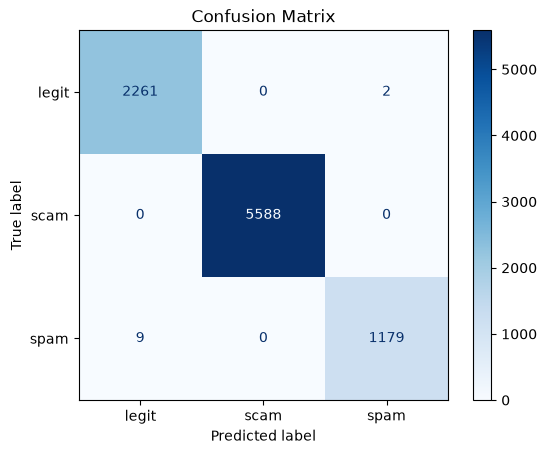

In [ ]:
# from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
# import matplotlib.pyplot as plt

# y_pred = model.predict(x_test)

# cm = confusion_matrix(
#     y_test,
#     y_pred,
#     labels=['legit', 'scam', 'spam']
# )

# disp = ConfusionMatrixDisplay(
#     confusion_matrix=cm,
#     display_labels=['legit', 'scam', 'spam']
# )

# disp.plot(cmap='Blues', values_format='d')
# plt.title("Confusion Matrix")
# plt.show()

In [ ]:
joblib.dump(model, 'SpamSMS.pkl')
print("Model saved successfully")

Model saved successfully
